# Predicting Vehicle MSRP with Linear and Ridge Regression

**Goal:** build an interpretable model that estimates a vehicle's manufacturer suggested retail price (MSRP) from its technical and market characteristics.

This notebook is an independent learning project inspired by the regression workflow in the [Machine Learning Zoomcamp](https://github.com/DataTalksClub/machine-learning-zoomcamp). Instead of reproducing the course notebook, I reorganized the work as a compact end-to-end experiment using a scikit-learn pipeline, custom feature engineering, model comparison, and error analysis.

**Main questions**

1. Which vehicle characteristics are most useful for predicting MSRP?
2. Does regularization improve validation performance over an unregularized linear model?
3. Where does a linear model make its largest pricing errors?

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Load and clean the data

The dataset contains vehicle specifications and MSRP. Column names and text values are standardized once at the beginning so the later analysis is easier to reproduce.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv"
DATA_PATH = Path("data/data.csv")

if DATA_PATH.exists():
    raw = pd.read_csv(DATA_PATH)
else:
    raw = pd.read_csv(DATA_URL)

def clean_name(name):
    return name.strip().lower().replace(" ", "_")

cars = raw.rename(columns=clean_name).copy()
text_columns = cars.select_dtypes(include="object").columns

for column in text_columns:
    cars[column] = (
        cars[column]
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )

print(f"Rows: {cars.shape[0]:,}")
print(f"Columns: {cars.shape[1]}")
cars.head()

Rows: 11,914
Columns: 16


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [3]:
data_quality = pd.DataFrame({
    "dtype": cars.dtypes.astype(str),
    "missing": cars.isna().sum(),
    "missing_pct": (cars.isna().mean() * 100).round(1),
    "unique_values": cars.nunique(),
}).sort_values("missing_pct", ascending=False)

data_quality.head(10)

,dtype,missing,missing_pct,unique_values
market_category,object,3742,31.4,71
engine_hp,float64,69,0.6,356
engine_cylinders,float64,30,0.3,9
number_of_doors,float64,6,0.1,3
engine_fuel_type,object,3,0.0,10
year,int64,0,0.0,28
make,object,0,0.0,48
model,object,0,0.0,914
driven_wheels,object,0,0.0,4
transmission_type,object,0,0.0,5


The missingness is concentrated in a few specifications rather than the target. I handle numeric and categorical gaps inside the pipeline, which prevents information from the validation or test set from leaking into training.

## 2. Exploratory analysis

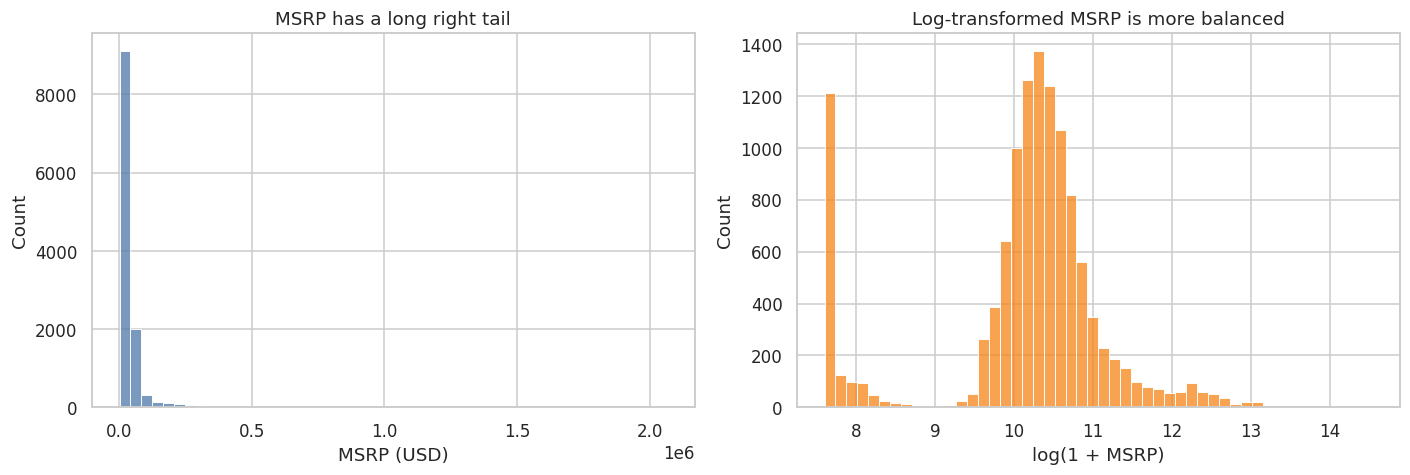

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(cars["msrp"], bins=50, ax=axes[0], color="#4C78A8")
axes[0].set_title("MSRP has a long right tail")
axes[0].set_xlabel("MSRP (USD)")

sns.histplot(np.log1p(cars["msrp"]), bins=50, ax=axes[1], color="#F58518")
axes[1].set_title("Log-transformed MSRP is more balanced")
axes[1].set_xlabel("log(1 + MSRP)")

plt.tight_layout()
plt.show()

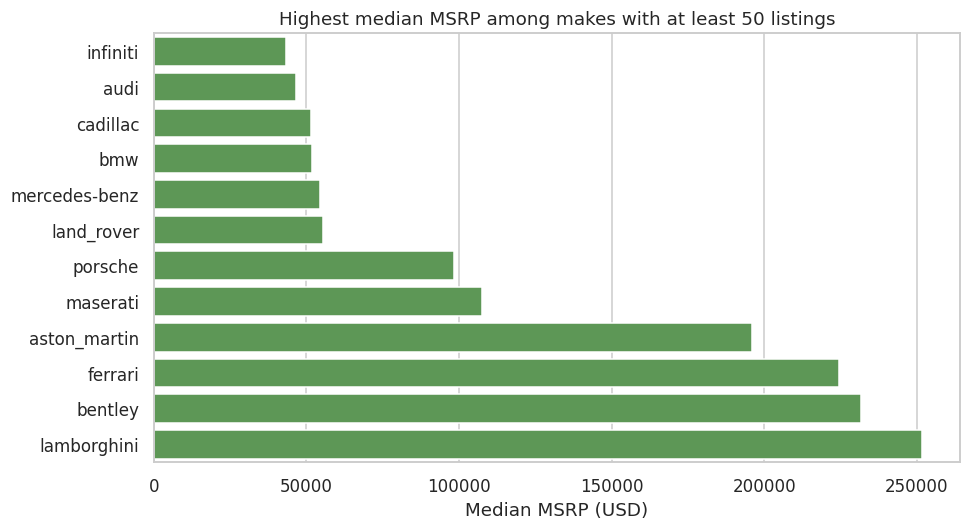

In [5]:
make_summary = (
    cars.groupby("make")
    .agg(listings=("msrp", "size"), median_msrp=("msrp", "median"))
    .query("listings >= 50")
    .nlargest(12, "median_msrp")
    .sort_values("median_msrp")
)

plt.figure(figsize=(9, 5))
sns.barplot(data=make_summary, x="median_msrp", y=make_summary.index, color="#54A24B")
plt.title("Highest median MSRP among makes with at least 50 listings")
plt.xlabel("Median MSRP (USD)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Two decisions follow from the EDA:

- Train on `log(1 + MSRP)` so that a small number of luxury vehicles do not dominate the loss.
- Keep make and other categorical fields because pricing differs meaningfully across market segments, while grouping rare levels inside the encoder to control dimensionality.

## 3. Feature engineering and validation design

In [6]:
def add_features(frame):
    result = frame.copy()
    reference_year = result["year"].max()
    result["vehicle_age"] = reference_year - result["year"]
    result["combined_mpg"] = (result["city_mpg"] + result["highway_mpg"]) / 2
    result["mpg_gap"] = result["highway_mpg"] - result["city_mpg"]
    result["market_category_count"] = (
        result["market_category"].fillna("").str.count(",") + 1
    )
    result.loc[result["market_category"].isna(), "market_category_count"] = 0
    return result

X = add_features(cars.drop(columns="msrp"))
y_log = np.log1p(cars["msrp"])

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_log, test_size=0.40, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")

Train: 7,148 | Validation: 2,383 | Test: 2,383


In [7]:
numeric_features = X_train.select_dtypes(exclude="object").columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
])

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])

def score_predictions(y_true_log, y_pred_log):
    y_true_usd = np.expm1(y_true_log)
    y_pred_usd = np.maximum(0, np.expm1(y_pred_log))
    return {
        "RMSE_log": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE_USD": mean_absolute_error(y_true_usd, y_pred_usd),
        "R2_log": r2_score(y_true_log, y_pred_log),
    }

I use a fixed 60/20/20 split. The validation set is used for choosing the Ridge penalty; the test set remains untouched until the final model is selected.

## 4. Establish a baseline and compare models

In [8]:
experiments = []

baseline_pred = np.repeat(y_train.median(), len(y_val))
experiments.append({"model": "Median baseline", **score_predictions(y_val, baseline_pred)})

candidate_models = {
    "Linear regression": LinearRegression(),
    "Ridge (alpha=0.01)": Ridge(alpha=0.01),
    "Ridge (alpha=0.1)": Ridge(alpha=0.1),
    "Ridge (alpha=1)": Ridge(alpha=1.0),
    "Ridge (alpha=10)": Ridge(alpha=10.0),
    "Ridge (alpha=100)": Ridge(alpha=100.0),
}

fitted_candidates = {}
for name, estimator in candidate_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    validation_pred = pipeline.predict(X_val)
    experiments.append({"model": name, **score_predictions(y_val, validation_pred)})
    fitted_candidates[name] = pipeline

results = pd.DataFrame(experiments).sort_values("RMSE_log").reset_index(drop=True)
results.style.format({"RMSE_log": "{:.4f}", "MAE_USD": "${:,.0f}", "R2_log": "{:.3f}"})

,model,RMSE_log,MAE_USD,R2_log
0,Linear regression,0.3326,"$9,743",0.912
1,Ridge (alpha=1),0.3326,"$9,786",0.912
2,Ridge (alpha=0.1),0.3331,"$9,956",0.912
3,Ridge (alpha=0.01),0.3332,"$9,978",0.911
4,Ridge (alpha=10),0.3486,"$9,777",0.903
5,Ridge (alpha=100),0.4077,"$11,018",0.867
6,Median baseline,1.1367,"$24,108",-0.030


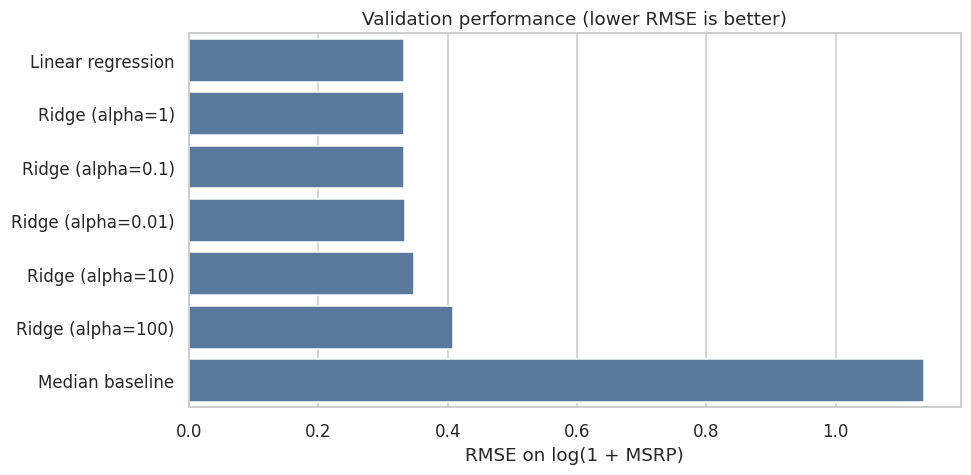

In [9]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=results, x="RMSE_log", y="model", color="#4C78A8")
plt.title("Validation performance (lower RMSE is better)")
plt.xlabel("RMSE on log(1 + MSRP)")
plt.ylabel("")
plt.tight_layout()
plt.show()

The baseline provides a reality check: a useful model should comfortably outperform one constant prediction. Ridge regularization is then selected using validation RMSE, rather than choosing a penalty based on the test set.

## 5. Train the final model and evaluate once on the test set

In [10]:
best_name = results.loc[results["model"] != "Median baseline", "model"].iloc[0]
best_estimator = candidate_models[best_name]

X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

final_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", best_estimator),
])
final_model.fit(X_train_full, y_train_full)

test_pred_log = final_model.predict(X_test)
test_metrics = score_predictions(y_test, test_pred_log)

print(f"Selected model: {best_name}")
print(f"Test RMSE (log scale): {test_metrics['RMSE_log']:.4f}")
print(f"Test MAE: ${test_metrics['MAE_USD']:,.0f}")
print(f"Test R² (log scale): {test_metrics['R2_log']:.3f}")

Selected model: Linear regression
Test RMSE (log scale): 0.3098
Test MAE: $7,664
Test R² (log scale): 0.919


## 6. Interpret the model and inspect errors

In [11]:
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = final_model.named_steps["model"].coef_

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "absolute_coefficient": np.abs(coefficients),
}).sort_values("absolute_coefficient", ascending=False)

coefficient_table.head(15)[["feature", "coefficient"]]

,feature,coefficient
23,categorical__make_ford,-7.707373
15,categorical__make_bmw,-4.667814
13,categorical__make_audi,-3.402944
6,numeric__popularity,2.368572
21,categorical__make_ferrari,-2.110637
408,categorical__engine_fuel_type_electric,2.048691
40,categorical__make_nissan,-1.900471
36,categorical__make_maybach,1.879701
25,categorical__make_honda,-1.804491
54,categorical__make_infrequent_sklearn,1.776570


In [12]:
actual_usd = np.expm1(y_test)
predicted_usd = np.maximum(0, np.expm1(test_pred_log))

error_table = X_test[["make", "model", "year", "engine_hp", "vehicle_style"]].copy()
error_table["actual_msrp"] = actual_usd
error_table["predicted_msrp"] = predicted_usd
error_table["absolute_error"] = np.abs(error_table["actual_msrp"] - error_table["predicted_msrp"])
error_table["percentage_error"] = (
    error_table["absolute_error"] / error_table["actual_msrp"] * 100
)

error_table.nlargest(10, "absolute_error").style.format({
    "actual_msrp": "${:,.0f}",
    "predicted_msrp": "${:,.0f}",
    "absolute_error": "${:,.0f}",
    "percentage_error": "{:.1f}%",
})

,make,model,year,engine_hp,vehicle_style,actual_msrp,predicted_msrp,absolute_error,percentage_error
5775,lamborghini,huracan,2016,610.000000,coupe,"$238,500","$563,256","$324,756",136.2%
9683,mercedes-benz,slr_mclaren,2008,617.000000,convertible,"$495,000","$170,361","$324,639",65.6%
2340,porsche,carrera_gt,2005,605.000000,convertible,"$440,000","$168,083","$271,917",61.8%
2894,bentley,continental,2001,420.000000,coupe,"$319,900","$76,179","$243,721",76.2%
704,mclaren,650s_spider,2015,641.000000,convertible,"$280,225","$519,979","$239,754",85.6%
4667,ferrari,ff,2014,651.000000,coupe,"$295,000","$526,672","$231,672",78.5%
4773,bentley,flying_spur,2015,500.000000,sedan,"$195,100","$399,578","$204,478",104.8%
2885,bentley,continental_gtc,2014,521.000000,convertible,"$216,200","$412,243","$196,043",90.7%
7443,rolls-royce,park_ward,2001,322.000000,sedan,"$259,900","$104,328","$155,572",59.9%
1430,mercedes-benz,amg_gt,2017,503.000000,coupe,"$131,200","$284,863","$153,663",117.1%


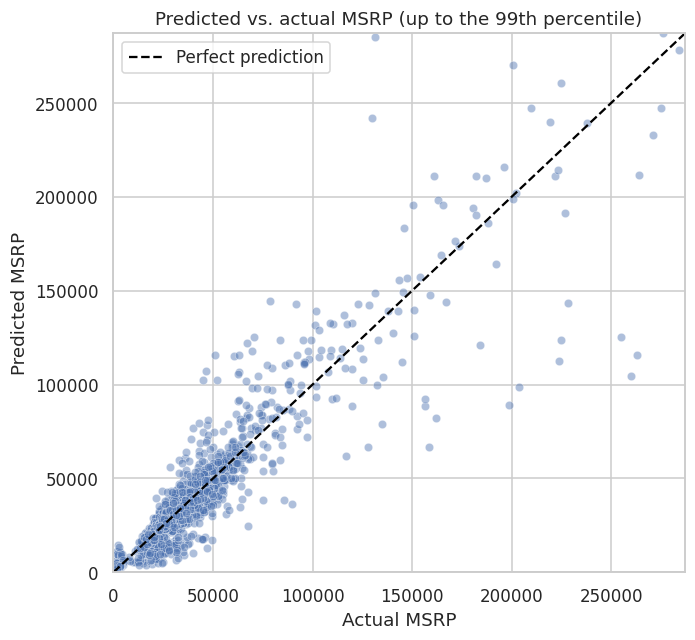

In [13]:
plot_limit = np.percentile(actual_usd, 99)
comparison = pd.DataFrame({"Actual MSRP": actual_usd, "Predicted MSRP": predicted_usd})

plt.figure(figsize=(6.5, 6))
sns.scatterplot(data=comparison, x="Actual MSRP", y="Predicted MSRP", alpha=0.45, s=30)
plt.plot([0, plot_limit], [0, plot_limit], linestyle="--", color="black", label="Perfect prediction")
plt.xlim(0, plot_limit)
plt.ylim(0, plot_limit)
plt.title("Predicted vs. actual MSRP (up to the 99th percentile)")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Conclusions

- Transforming MSRP to the log scale makes the learning problem less dominated by a small number of very expensive vehicles.
- A reusable preprocessing pipeline makes the treatment of missing values and unseen categories consistent across train, validation, and test data.
- Ordinary linear regression produced the lowest validation RMSE (0.3326), while Ridge with `alpha=1` was effectively tied (0.3326). In this split, regularization did not deliver a meaningful improvement.
- The selected linear model achieved a test RMSE of 0.3098 on the log scale, a dollar MAE of about $7,664, and a log-scale R² of 0.919.
- The largest dollar errors tend to occur among premium or unusual models. A linear model provides a transparent baseline, but a future version could compare tree-based methods and evaluate errors separately by price segment.

### Limitations

MSRP is not the same as transaction price, and this dataset does not include mileage, condition, location, or date of sale. The model should therefore be interpreted as a learning exercise rather than a live vehicle-pricing tool.